# Notebook 1. One place, one moment

> Readable here as is; to run it, `./scripts/fetch_data.sh` downloads about 2.5 GB.

**The question:** *Standing at one spot near the Moon's south pole, at one exact moment, where are the Sun and the Earth in the sky? Are they above the skyline? And can a Deep Space Network dish on Earth hear us?*

That is the whole notebook. One place. One instant. No tricks.

We use only a few tools: **SPICE** (NASA's ephemeris toolkit) for where things are, **numpy** for arithmetic, and **matplotlib** for pictures. Nothing here imports the app's own code. We redo the small, honest core of it, so you can see every step.

The steps follow *How It Works in One Page* in the User Guide (`docs/learn/lunazen_guide.pdf`):

| Step | Question |
|---|---|
| 1 | What time is it, for the computer? |
| 2 | Where are the Sun and the Earth? |
| 3 | Which way is up, east and north *here*? |
| 4 | What does the skyline look like? |
| 5 | Is each body above the skyline? Can the DSN hear us? |

The notebook does Steps 1 to 5 for one moment. Step 6 (many moments) is in notebook 2, `02_one_place_many_moments`.

> **Before you start.** Run `./scripts/fetch_data.sh` once from the project folder. It downloads the data this notebook reads: the SPICE kernels (where the Sun, Earth and Moon are) and the LOLA 20 m terrain map (the heights of the ground). About 2.5 GB in all, and it skips what you already have. Without it the cells below cannot find their files.

In [1]:
import os
import numpy as np
import spiceypy as spice
import matplotlib.pyplot as plt

# Colours as in the guides: blue, red, green and gold.
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
                     "axes.prop_cycle": plt.cycler(color=["#1f4e9c", "#c0272d", "#2e8b57", "#f0a30a"]),
                     "axes.titlecolor": "#14357a", "axes.labelcolor": "#14357a"})
np.set_printoptions(precision=4, suppress=True)

# Find the project folder (the one holding scripts/fetch_data.sh), wherever Jupyter was started.
root = os.getcwd()
while not os.path.exists(os.path.join(root, "scripts", "fetch_data.sh")):
    parent = os.path.dirname(root)
    if parent == root:
        raise FileNotFoundError("Run this notebook from inside the project folder.")
    root = parent

# Where the downloaded data lives (scripts/fetch_data.sh puts it here).
DATA = os.path.join(root, "data", "external")
KERNELS = os.path.join(DATA, "kernels")
LOLA = os.path.join(DATA, "lola")
if not (os.path.exists(os.path.join(KERNELS, "de440s.bsp")) and os.path.exists(os.path.join(LOLA, "LDEM_85S_20M.IMG"))):
    raise FileNotFoundError("Data is missing. Run ./scripts/fetch_data.sh from the project folder first.")

## Our spot and our moment

We pick **Site01-1**, a spot on the *Connecting ridge* near the south pole. NASA's published average-illumination map marks this ridge as one of the best-lit places on the Moon. The coordinates come from our candidate-spot product, which was built from NASA's PGDA data.

We pick one moment: **1 March 2027, 06:15 UTC**. A lander is at the spot, and its camera and antenna sit on a **2 m mast**.

In [2]:
LAT_DEG = -89.47485136585945      # planetocentric latitude
LON_DEG = 222.55686188749715      # east longitude
GROUND_M = 1947.36                # height of the ground above the 1737.4 km sphere (the 5 m NASA tile's value; the 20 m map below gives 1947.0)
MAST_M = 2.0                      # antenna / camera height
R_MOON = 1_737_400.0              # lunar reference sphere, metres (matches LOLA)

UTC = "2027-03-01T06:15:00"

## Step 1. What time is it, for the computer?

People say "6:15 on 1 March". The computer needs one number. SPICE uses **ET**: seconds since noon on 1 January 2000, counted on a perfectly steady clock (called TDB).

Why not plain UTC? Because UTC adds leap seconds now and then to keep up with Earth's slowing spin. A steady clock cannot jump. So SPICE converts with a table of leap seconds (a file called `naif0012.tls`).

First, load the kernels. A *kernel* is just a data file SPICE reads. We need five.

In [3]:
KERNEL_FILES = {
    "naif0012.tls":          "leap seconds",
    "pck00011.tpc":          "planet sizes and spin (Earth's orientation lives here)",
    "moon_de440_250416.tf":  "names of the Moon's frames, e.g. MOON_ME",
    "moon_pa_de440_200625.bpc": "the Moon's orientation, very accurately",
    "de440s.bsp":            "positions of Sun, Earth, Moon (DE440, 1849 to 2150)",
}
spice.kclear()
for name, what in KERNEL_FILES.items():
    path = os.path.join(KERNELS, name)
    spice.furnsh(path)
    print(f"{name:28s} {os.path.getsize(path)/1e6:8.2f} MB   {what}")

naif0012.tls                     0.01 MB   leap seconds
pck00011.tpc                     0.13 MB   planet sizes and spin (Earth's orientation lives here)
moon_de440_250416.tf             0.02 MB   names of the Moon's frames, e.g. MOON_ME
moon_pa_de440_200625.bpc        12.86 MB   the Moon's orientation, very accurately
de440s.bsp                      32.73 MB   positions of Sun, Earth, Moon (DE440, 1849 to 2150)


In [4]:
et = spice.str2et(UTC)
print(f"UTC {UTC}  ->  ET = {et:,.3f} s past J2000")

# By hand: seconds on a plain calendar clock since 2000-01-01 12:00, plus 37 leap seconds and 32.184 s.
from datetime import datetime
plain = (datetime.fromisoformat(UTC) - datetime(2000, 1, 1, 12, 0, 0)).total_seconds()
by_hand = plain + 37 + 32.184
print(f"by hand: {plain:,.0f} + 37 + 32.184 = {by_hand:,.3f} s")
print(f"SPICE  : {et:,.3f} s     difference {1000 * (et - by_hand):.1f} ms")

UTC 2027-03-01T06:15:00  ->  ET = 857,153,769.185 s past J2000
by hand: 857,153,700 + 37 + 32.184 = 857,153,769.184 s
SPICE  : 857,153,769.185 s     difference 1.4 ms


**Check by hand.** The cell above did it: the plain clock count, plus the leap seconds, plus 32.184 s. TAI runs ahead of UTC by the leap seconds, and TDB is 32.184 s ahead of TAI (plus a tiny wobble of about 1.6 ms from Earth's orbit). In 2027 the leap-second count is 37. So ET should lead plain UTC by about 37 + 32.184 = **69.184 s**. The last line shows the difference from SPICE: about a millisecond, which is that orbital wobble. (The by-hand sum lands within 1.7 ms of SPICE, never more.)

> **Try it.** Change `UTC` to a date in 2016 (before the last leap second). The gap changes by one second. That is a leap second at work.

## Step 2. Where are the Sun and the Earth?

We ask SPICE for a **position vector**: an arrow from the Moon's centre to the Sun, and another to the Earth. Three choices go into the question.

1. **Frame.** Numbers in an arrow depend on the axes. We want axes fixed to the Moon, called **MOON_ME** ("mean Earth / polar axis"). The x-axis points to the middle of the Earth-facing side, z to the north pole. These are the axes that LOLA's latitude and longitude use too.
2. **Light time and aberration.** Light takes time to travel. We want the direction we *see*. The setting `"LT+S"` tells SPICE to account for the light's travel time and for the observer's own motion.
3. **Units.** SPICE returns kilometres. We convert to metres at once.

In [5]:
def moon_to(body, frame="MOON_ME"):
    pos_km, light_time = spice.spkpos(body, et, frame, "LT+S", "MOON")
    return np.array(pos_km) * 1000.0, light_time

sun_vec, sun_lt = moon_to("SUN")
earth_vec, earth_lt = moon_to("EARTH")

for name, v, lt in (("Sun", sun_vec, sun_lt), ("Earth", earth_vec, earth_lt)):
    d = np.linalg.norm(v)
    lon = np.degrees(np.arctan2(v[1], v[0]))
    lat = np.degrees(np.arcsin(v[2] / d))
    print(f"{name:5s}  distance {d/1000:>13,.0f} km   light time {lt:7.1f} s   "
          f"sub-body longitude {lon:7.1f} deg   latitude {lat:5.2f} deg")

Sun    distance   148,130,187 km   light time   494.1 s   sub-body longitude   -97.7 deg   latitude  0.57 deg
Earth  distance       402,917 km   light time     1.3 s   sub-body longitude     3.7 deg   latitude  5.82 deg


Read the result like this:

* The **Sun** is about 148 million km away. Its light takes about 494 s (over 8 minutes) to arrive.
* The **Earth** is about 403 000 km away: just over a second of light time.
* The *longitude* and *latitude* printed are where each body is straight overhead, on the Moon.

The Sun's sub-point is at longitude about −98°. That is over the far side. Our spot sits near the pole, so the Sun is nowhere near overhead. Keep going.

**A picture of the frames.** The same arrows exist in a space-fixed frame (J2000) too. Only the axes differ. Watch how the arrows look in the two.

Rotating the J2000 Earth arrow into MOON_ME gives the same vector as asking SPICE directly:
  by rotation: [399983.0275  26196.1565  40854.7999] km
  from SPICE : [399983.0275  26196.1565  40854.7999] km


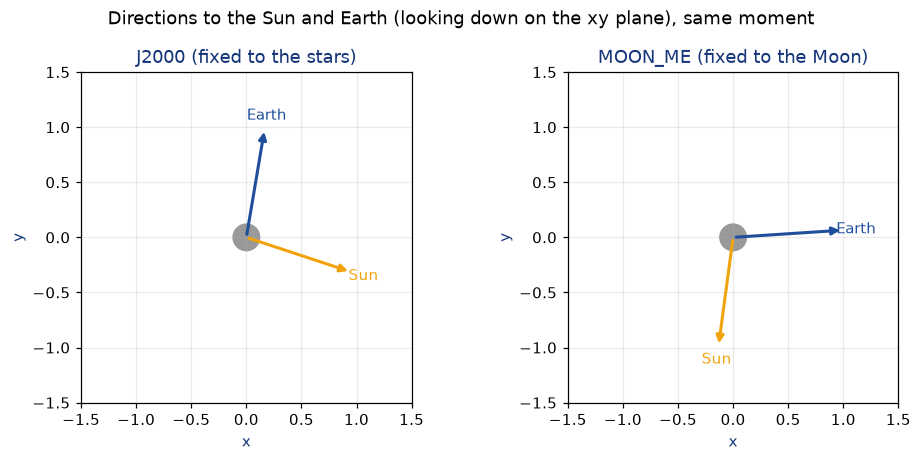

In [6]:
sun_j2000, _ = spice.spkpos("SUN", et, "J2000", "LT+S", "MOON")
earth_j2000, _ = spice.spkpos("EARTH", et, "J2000", "LT+S", "MOON")
sun_j2000 = np.array(sun_j2000) * 1000.0
earth_j2000 = np.array(earth_j2000) * 1000.0

# The rotation between the two frames
rot = np.array(spice.pxform("J2000", "MOON_ME", et))
print("Rotating the J2000 Earth arrow into MOON_ME gives the same vector as asking SPICE directly:")
print("  by rotation:", rot @ earth_j2000 / 1000.0, "km")
print("  from SPICE :", earth_vec / 1000.0, "km")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), subplot_kw={"projection": None})
for ax, (title, s, e) in zip(axes, (("J2000 (fixed to the stars)", sun_j2000, earth_j2000),
                                    ("MOON_ME (fixed to the Moon)", sun_vec, earth_vec))):
    for v, col, lab in ((s, "#f0a30a", "Sun"), (e, "#1f4e9c", "Earth")):
        u = v[:2] / np.linalg.norm(v[:2])
        ax.annotate("", xy=u, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
        ax.text(*(1.12 * u), lab, color=col, ha="center", va="center")
    ax.add_patch(plt.Circle((0, 0), 0.12, color="0.6"))
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal")
    ax.set_title(title); ax.set_xlabel("x"); ax.set_ylabel("y")
fig.suptitle("Directions to the Sun and Earth (looking down on the xy plane), same moment")
fig.tight_layout()

The arrows are the same arrows; only the axes turned. In MOON_ME the Earth stays near the +x axis (the Moon always shows us nearly the same face). The wobble of a few degrees around +x is **libration**: the Moon nods and turns a little, so we see slightly more than half of it over time.

**What is inside the kernels?** Neither big file is a table of answers. Each holds, for short stretches of time, the coefficients of a **Chebyshev polynomial**, and SPICE evaluates the polynomial at your ET. (Kernel "type 2" means exactly this.) The positions in `de440s.bsp` are stored relative to *barycentres* (centres of mass), and SPICE chains them. J2000 only fixes the axes; the origin is whatever you ask for. The Moon's orientation (`.bpc`) is also a Chebyshev fit, so MOON_PA, and MOON_ME with its fixed extra rotation, change with time. Look for yourself:

In [7]:
def segments(path):
    handle = spice.dafopr(path); spice.dafbfs(handle); out = []
    while spice.daffna():
        _, ic = spice.dafus(spice.dafgs(), 2, 6)
        out.append((int(ic[0]), int(ic[1]), int(ic[3] if path.endswith(".bsp") else ic[2])))
    spice.dafcls(handle); return out

NAMES = {0: "solar system barycentre", 3: "Earth-Moon barycentre", 10: "Sun", 399: "Earth", 301: "Moon"}
for body, centre, kind in segments(os.path.join(KERNELS, "de440s.bsp")):
    if body in NAMES:
        print(f"{NAMES[body]:24s} relative to {NAMES.get(centre, centre):24s} data type {kind} (Chebyshev)")
print("Moon orientation segments (body, frame, type):", segments(os.path.join(KERNELS, "moon_pa_de440_200625.bpc")))

Earth-Moon barycentre    relative to solar system barycentre  data type 2 (Chebyshev)
Sun                      relative to solar system barycentre  data type 2 (Chebyshev)
Moon                     relative to Earth-Moon barycentre    data type 2 (Chebyshev)
Earth                    relative to Earth-Moon barycentre    data type 2 (Chebyshev)
Moon orientation segments (body, frame, type): [(31008, 1, 2), (31008, 1, 2)]


**The frame chain.** J2000 reaches MOON_ME in two steps: a time-varying rotation to MOON_PA (three angles from the `.bpc`, carrying the Moon's spin and libration), then a constant rotation of 0.029° (about 875 m on the surface) to MOON_ME. SPICE multiplies them for you, and we can check it:

In [8]:
to_pa = np.array(spice.pxform("J2000", "MOON_PA", et))
pa_to_me = np.array(spice.pxform("MOON_PA", "MOON_ME", et))
to_me = np.array(spice.pxform("J2000", "MOON_ME", et))
print("J2000 -> MOON_ME equals (MOON_PA -> MOON_ME) @ (J2000 -> MOON_PA):", np.allclose(to_me, pa_to_me @ to_pa, atol=1e-12))
print("The constant link turns by", round(np.degrees(np.arccos((np.trace(pa_to_me) - 1) / 2)), 4), "degrees")
et2 = et + 86400
turn = np.array(spice.pxform("J2000", "MOON_PA", et2)) @ to_pa.T
print("The time-varying link turns by", round(np.degrees(np.arccos((np.trace(turn) - 1) / 2)), 2), "degrees in one day")

J2000 -> MOON_ME equals (MOON_PA -> MOON_ME) @ (J2000 -> MOON_PA): True
The constant link turns by 0.0289 degrees
The time-varying link turns by 13.18 degrees in one day


## Step 3. Which way is up, east and north *here*?

An arrow in MOON_ME says where the Sun is, but our spot cares about *its own* sky. So we build a small coordinate system standing on the ground at the spot:

* **Up**: straight away from the Moon's centre.
* **East**: along the direction of increasing longitude.
* **North**: toward the north pole, along the ground.

This is called **ENU** (east, north, up). In terms of latitude $\varphi$ and longitude $\lambda$:

$$
\hat e = (-\sin\lambda,\ \cos\lambda,\ 0),\quad
\hat n = (-\sin\varphi\cos\lambda,\ -\sin\varphi\sin\lambda,\ \cos\varphi),\quad
\hat u = (\cos\varphi\cos\lambda,\ \cos\varphi\sin\lambda,\ \sin\varphi).
$$

The spot's own arrow from the Moon's centre is $(R + z_0 + h)\,\hat u$, where $z_0$ is the ground height and $h$ the mast.

In [9]:
lat, lon = np.radians(LAT_DEG), np.radians(LON_DEG)

east  = np.array([-np.sin(lon), np.cos(lon), 0.0])
north = np.array([-np.sin(lat) * np.cos(lon), -np.sin(lat) * np.sin(lon), np.cos(lat)])
up    = np.array([ np.cos(lat) * np.cos(lon),  np.cos(lat) * np.sin(lon), np.sin(lat)])

site = (R_MOON + GROUND_M + MAST_M) * up   # lander antenna position in MOON_ME

# A good set of axes is perpendicular, unit length, and right-handed.
print("e.n =", east @ north, "  e.u =", east @ up, "  n.u =", north @ up)
print("e x n = u ?", np.allclose(np.cross(east, north), up))
print("antenna distance from Moon's centre:", f"{np.linalg.norm(site):,.1f} m")

e.n = 5.551115123125783e-17   e.u = 0.0   n.u = 0.0
e x n = u ? True
antenna distance from Moon's centre: 1,739,349.4 m


Now take the arrow **from the antenna to the Sun** (Sun arrow minus our arrow) and ask three things: how far east, how far north, how far up?

$$
\text{azimuth } A = \operatorname{atan2}(\vec v\cdot\hat e,\ \vec v\cdot\hat n),\qquad
\text{elevation } E = \operatorname{atan2}\!\Big(\vec v\cdot\hat u,\ \sqrt{(\vec v\cdot\hat e)^2+(\vec v\cdot\hat n)^2}\Big).
$$

Azimuth is measured from north, clockwise as seen from above (0° north, 90° east, 180° south, 270° west). Elevation is the angle above the local flat ground; below zero means under the ground plane.

In [10]:
def az_el(vec_moon_centre_to_body):
    v = vec_moon_centre_to_body - site        # parallax: from the antenna, not the Moon's centre
    e, n, u = v @ east, v @ north, v @ up
    az = np.degrees(np.arctan2(e, n)) % 360.0
    el = np.degrees(np.arctan2(u, np.hypot(e, n)))
    return az, el, np.linalg.norm(v)

sun_az, sun_el, sun_dist = az_el(sun_vec)
earth_az, earth_el, earth_dist = az_el(earth_vec)
print(f"Sun   azimuth {sun_az:6.2f} deg   elevation {sun_el:6.2f} deg")
print(f"Earth azimuth {earth_az:6.2f} deg   elevation {earth_el:6.2f} deg")

Sun   azimuth  39.78 deg   elevation  -0.17 deg
Earth azimuth 141.16 deg   elevation  -6.47 deg


**Why subtract the spot's arrow?** For the Sun, it barely matters (the Sun is so far away). For the Earth it matters a little, because we stand 1737 km from the Moon's centre and the Earth is 400 000 km away: the shift is about a quarter of a degree. That shift is called **parallax**. It is the same effect as seeing a nearby tree move against the hills when you walk.

Both bodies are **close to the flat horizon** (elevation near 0° for the Sun, a few degrees below for the Earth). That is exactly the south pole's strange sky: the Sun skims around the horizon instead of rising high. Whether we actually *see* either depends on the terrain.

## Interlude. The polar sky, and how big the bodies look

A body is not a point. It is a disk, and its angular radius follows from its size and distance:

$$
\rho = \arcsin\!\left(\frac{R_\text{body}}{D}\right).
$$

The Sun has $R = 695\,700$ km. The Earth, for our purposes, has its equatorial radius $6378.137$ km.

In [11]:
SUN_RADIUS_M, EARTH_RADIUS_M = 695_700_000.0, 6_378_137.0
sun_rad = np.degrees(np.arcsin(SUN_RADIUS_M / sun_dist))
earth_rad = np.degrees(np.arcsin(EARTH_RADIUS_M / earth_dist))
print(f"Sun   angular radius {sun_rad:.3f} deg   (diameter {2*sun_rad*60:.1f} arcmin)")
print(f"Earth angular radius {earth_rad:.3f} deg   (diameter {2*earth_rad*60:.1f} arcmin)")

Sun   angular radius 0.269 deg   (diameter 32.3 arcmin)
Earth angular radius 0.907 deg   (diameter 108.8 arcmin)


The Sun is about half a degree across. The Earth looks about 1.8° across, more than three times wider. A body can be *partly* above the skyline, and we count it as **up when any part of its disk is above the terrain**.

## Interlude. The terrain map

To know what hides the sky we need a map of heights. We use **LOLA** (the Lunar Orbiter Laser Altimeter on NASA's LRO spacecraft). The file `LDEM_85S_20M` covers everything south of 85°S with one height every **20 m**.

It comes as two files:

* a **label** (`.LBL`): plain text saying how to read the data;
* an **image** (`.IMG`): a big block of numbers, 15 168 rows by 15 168 columns, each a 16-bit integer.

A stored number $N$ turns into a height by $z = 0.5\,N$ metres, measured above the 1737.4 km sphere.

In [12]:
label = open(os.path.join(LOLA, "LDEM_85S_20M.LBL"), errors="replace").read()
import re
def lab(key):
    return re.search(rf"^\s*{key}\s*=\s*([^\s<]+)", label, re.M).group(1).strip('"')

N = int(lab("LINES"))
SCALE_M = float(re.search(r"MAP_SCALE\s*=\s*([\d.]+)", label).group(1)) * (1000 if "km" in re.search(r"MAP_SCALE\s*=.*", label).group(0) else 1)
LINE_OFF = float(re.search(r"LINE_PROJECTION_OFFSET\s*=\s*([-\d.]+)", label).group(1))
SAMPLE_OFF = float(re.search(r"SAMPLE_PROJECTION_OFFSET\s*=\s*([-\d.]+)", label).group(1))
FACTOR = float(lab("SCALING_FACTOR"))
print("grid:", N, "x", N, "   pixel size:", SCALE_M, "m   scale:", FACTOR, "m per count")
print("projection offsets (line, sample):", LINE_OFF, SAMPLE_OFF)

# 'memmap' means: do not load 460 MB, just look at the file where we need it.
raw = np.memmap(os.path.join(LOLA, "LDEM_85S_20M.IMG"), dtype="<i2", mode="r", shape=(N, N))
print("height at map centre (the pole):", raw[N // 2, N // 2] * FACTOR, "m")

grid: 15168 x 15168    pixel size: 20.0 m   scale: 0.5 m per count
projection offsets (line, sample): 7583.5 7583.5
height at map centre (the pole): 1288.5 m


### From latitude and longitude to a pixel

The map uses a **polar stereographic projection**. Imagine a light at the north pole, and a sheet of paper touching the south pole. Each point on the Moon casts a shadow on the paper. Distances from the pole are

$$
\rho = 2R\tan\!\Big(\frac{\pi/2+\varphi}{2}\Big),\qquad x=\rho\sin\lambda,\qquad y=\rho\cos\lambda .
$$

($\varphi$ is negative in the south. At the pole, $\rho=0$.) Then pixel position follows from the pixel size and the label's offsets.

In [13]:
def to_xy(lat_rad, lon_rad):
    rho = 2.0 * R_MOON * np.tan((np.pi / 2.0 + lat_rad) / 2.0)
    return rho * np.sin(lon_rad), rho * np.cos(lon_rad)

def to_pixel(x, y):
    # column grows with x, row grows as y falls; the label's offsets already refer to pixel centres
    col = x / SCALE_M + SAMPLE_OFF
    row = LINE_OFF - y / SCALE_M
    return row, col

x0, y0 = to_xy(lat, lon)
print(f"spot: x = {x0:,.1f} m, y = {y0:,.1f} m, distance from the pole {np.hypot(x0, y0):,.0f} m")
print("pixel (row, col):", to_pixel(x0, y0))

spot: x = -10,770.0 m, y = -11,730.0 m, distance from the pole 15,924 m
pixel (row, col): (np.float64(8170.0000000000055), np.float64(7044.999999999995))


### Reading a height between pixels

The spot rarely falls exactly on a pixel centre. So we blend the four neighbouring pixels, weighting by closeness. This is **bilinear interpolation**. In one line: with the fractions $a,b$ along row and column,

$$
z = (1-a)(1-b)\,z_{00}+(1-a)\,b\,z_{01}+a(1-b)\,z_{10}+a\,b\,z_{11}.
$$

In [14]:
def height_at(rows, cols):
    rows, cols = np.asarray(rows, float), np.asarray(cols, float)
    r0 = np.floor(rows).astype(int); c0 = np.floor(cols).astype(int)
    a, b = rows - r0, cols - c0
    inside = (r0 >= 0) & (c0 >= 0) & (r0 < N - 1) & (c0 < N - 1)
    r0c, c0c = np.clip(r0, 0, N - 2), np.clip(c0, 0, N - 2)
    z = ((1 - a) * (1 - b) * raw[r0c, c0c] + (1 - a) * b * raw[r0c, c0c + 1]
         + a * (1 - b) * raw[r0c + 1, c0c] + a * b * raw[r0c + 1, c0c + 1]) * FACTOR
    return np.where(inside, z, np.nan)

r0_, c0_ = to_pixel(x0, y0)
ground = float(height_at(r0_, c0_))
print(f"ground height under the spot, LOLA 20 m: {ground:.1f} m   (the app's 5 m tile says {GROUND_M:.1f} m)")

ground height under the spot, LOLA 20 m: 1947.0 m   (the app's 5 m tile says 1947.4 m)


The two heights differ by a few metres: the app also uses a finer 5 m tile around the spot, and the 20 m map smooths small bumps. We will use the 20 m height from here on, so the notebook is self-consistent.

In [15]:
GROUND_M = ground
site = (R_MOON + GROUND_M + MAST_M) * up
sun_az, sun_el, sun_dist = az_el(sun_vec)
earth_az, earth_el, earth_dist = az_el(earth_vec)
sun_rad = np.degrees(np.arcsin(SUN_RADIUS_M / sun_dist))
earth_rad = np.degrees(np.arcsin(EARTH_RADIUS_M / earth_dist))
print(f"Sun   az {sun_az:7.3f}   el {sun_el:7.3f}   r {sun_rad:.3f}")
print(f"Earth az {earth_az:7.3f}  el {earth_el:7.3f}   r {earth_rad:.3f}")

Sun   az  39.782   el  -0.172   r 0.269
Earth az 141.156  el  -6.475   r 0.907


### A picture of the neighbourhood

Here is a 20 km by 20 km piece of the map around the spot, shaded so that slopes facing the Sun's low light look bright. Spot in the middle.

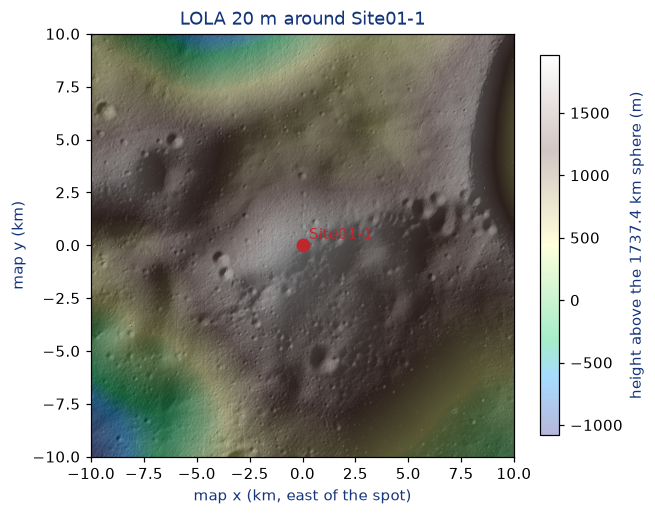

In [16]:
half = 10_000.0
n_pix = int(2 * half / SCALE_M)
xs = x0 + (np.arange(n_pix) - n_pix / 2) * SCALE_M
ys = y0 + (np.arange(n_pix) - n_pix / 2) * SCALE_M
X, Y = np.meshgrid(xs, ys[::-1])
rr, cc = to_pixel(X, Y)
Z = height_at(rr, cc)

# simple hillshade, with a low light from the upper left
gy, gx = np.gradient(Z, SCALE_M)
az_l, el_l = np.radians(300), np.radians(10)
slope = np.arctan(np.hypot(gx, gy)); aspect = np.arctan2(-gx, gy)
shade = np.sin(el_l) * np.cos(slope) + np.cos(el_l) * np.sin(slope) * np.cos(az_l - aspect)

fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.imshow(shade, extent=[-half/1000, half/1000, -half/1000, half/1000], cmap="gray", vmin=0, vmax=1)
im = ax.imshow(Z, extent=[-half/1000, half/1000, -half/1000, half/1000], cmap="terrain", alpha=0.35)
ax.plot(0, 0, "o", color="#c0272d", ms=8); ax.text(0.3, 0.3, "Site01-1", color="#c0272d")
ax.set_xlabel("map x (km, east of the spot)"); ax.set_ylabel("map y (km)")
ax.grid(False); fig.colorbar(im, label="height above the 1737.4 km sphere (m)", shrink=0.8)
ax.set_title("LOLA 20 m around Site01-1");

## Step 4. What does the skyline look like?

Now the clever bit. Stand at the spot and look in one direction, say azimuth $A$. A ridge at distance $s$ along the ground and height $z$ above the sphere makes a bump in the sky. How high does that bump look? The Moon's surface curves away from us, and we stand on a mast. So the angle is

$$
\varepsilon(s) = \arctan\!\left(\frac{r_1\cos\delta - r_0}{r_1\sin\delta}\right),\qquad
\delta=\frac{s}{R},\quad r_0=R+z_0+h,\quad r_1=R+z(s).
$$

Here $\delta$ is the angle at the Moon's centre between us and the ridge. The skyline at that direction is the **largest** $\varepsilon$ over all the distances we can see:

$$
H(A)=\max_s\ \varepsilon(s).
$$

We start at 10 m from the spot (10 m is the smallest distance the code looks at), step outward by $\max(5\text{ m},\ s/400)$ (finer close up, coarser far away), and go out to 300 km.

**To walk along a bearing** from the spot we need to find where we end up: go a central angle $\delta$ along azimuth $A$ on the sphere, and read off the new latitude and longitude. That is the "destination" formula from navigation.

In [17]:
def destination(lat_r, lon_r, az_r, delta):
    lat2 = np.arcsin(np.sin(lat_r) * np.cos(delta) + np.cos(lat_r) * np.sin(delta) * np.cos(az_r))
    lon2 = lon_r + np.arctan2(np.sin(az_r) * np.sin(delta) * np.cos(lat_r),
                              np.cos(delta) - np.sin(lat_r) * np.sin(lat2))
    return lat2, lon2

def distances(min_m=10.0, max_m=300_000.0, step_min=5.0, k=400.0):
    out, s = [], min_m
    while s <= max_m:
        out.append(s); s += max(step_min, s / k)
    return np.array(out)

S = distances()
print(len(S), "steps along each ray, from", S[0], "m to", S[-1], "m")

2405 steps along each ray, from 10.0 m to 299432.4528086353 m


In [18]:
r0_obs = R_MOON + GROUND_M + MAST_M

def elevation_profile(az_deg):
    delta = S / R_MOON
    la, lo = destination(lat, lon, np.radians(az_deg), delta)
    rr, cc = to_pixel(*to_xy(la, lo))
    z = height_at(rr, cc)                     # NaN where the ray leaves the map
    r1 = R_MOON + z
    eps = np.degrees(np.arctan2(r1 * np.cos(delta) - r0_obs, r1 * np.sin(delta)))
    return z, eps

# one direction first: towards the Sun
z_prof, eps_prof = elevation_profile(sun_az)
i_max = np.nanargmax(eps_prof)
print(f"Looking at azimuth {sun_az:.1f} deg:")
print(f"  skyline elevation {eps_prof[i_max]:.3f} deg, set by terrain {S[i_max]:,.0f} m away "
      f"(height {z_prof[i_max]:.0f} m)")

Looking at azimuth 39.8 deg:
  skyline elevation -0.578 deg, set by terrain 60 m away (height 1948 m)


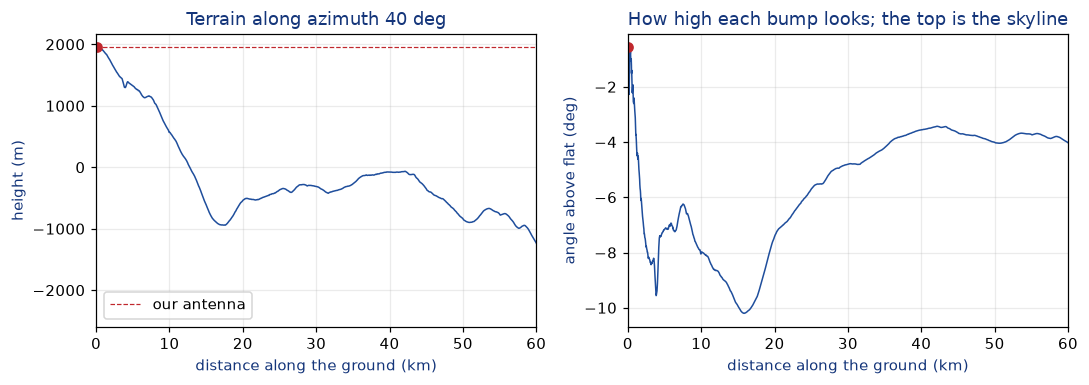

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(S / 1000, z_prof, lw=1)
ax[0].axhline(GROUND_M + MAST_M, color="#c0272d", ls="--", lw=0.8, label="our antenna")
ax[0].plot(S[i_max] / 1000, z_prof[i_max], "o", color="#c0272d")
ax[0].set_xlim(0, 60); ax[0].set_xlabel("distance along the ground (km)"); ax[0].set_ylabel("height (m)")
ax[0].set_title(f"Terrain along azimuth {sun_az:.0f} deg"); ax[0].legend()
ax[1].plot(S / 1000, eps_prof, lw=1)
ax[1].plot(S[i_max] / 1000, eps_prof[i_max], "o", color="#c0272d")
ax[1].set_xlim(0, 60); ax[1].set_xlabel("distance along the ground (km)"); ax[1].set_ylabel("angle above flat (deg)")
ax[1].set_title("How high each bump looks; the top is the skyline")
fig.tight_layout()

The curve on the right is the angle each piece of terrain appears at. Its highest point is what blocks the sky in that direction. Far hills look low, because the Moon's surface curves them down; near bumps can look tall.

Now do it for **every direction**, one ray every 0.25° of azimuth (1440 rays).

In [20]:
%%time
AZ = np.arange(0.0, 360.0, 0.25)
HORIZON = np.empty_like(AZ)
for i, a in enumerate(AZ):
    HORIZON[i] = np.nanmax(elevation_profile(a)[1])

def horizon_at(a):
    # linear interpolation, wrapping around 360 degrees
    return np.interp(np.asarray(a) % 360.0, np.append(AZ, 360.0), np.append(HORIZON, HORIZON[0]))

print(f"skyline: min {HORIZON.min():.2f} deg, max {HORIZON.max():.2f} deg")
print(f"skyline towards the Sun   (az {sun_az:.1f}): {horizon_at(sun_az):.3f} deg")
print(f"skyline towards the Earth (az {earth_az:.1f}): {horizon_at(earth_az):.3f} deg")

skyline: min -2.85 deg, max 0.66 deg
skyline towards the Sun   (az 39.8): -0.578 deg
skyline towards the Earth (az 141.2): -0.969 deg
CPU times: user 240 ms, sys: 80.1 ms, total: 320 ms
Wall time: 1.32 s


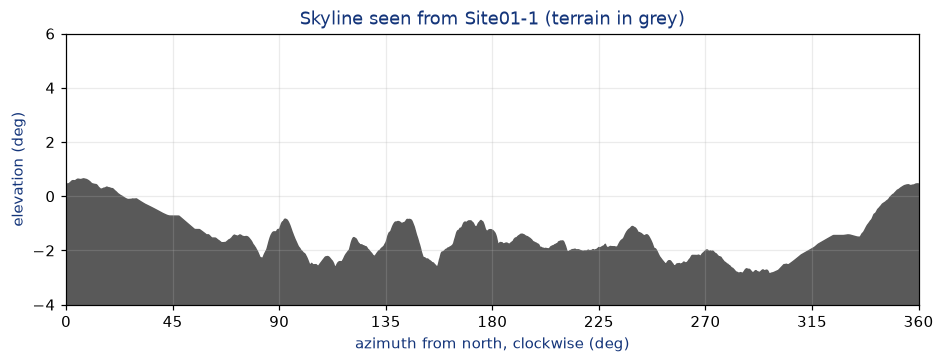

In [21]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.fill_between(AZ, -10, HORIZON, color="0.35")
ax.set_ylim(-4, max(6, HORIZON.max() + 1)); ax.set_xlim(0, 360)
ax.set_xlabel("azimuth from north, clockwise (deg)"); ax.set_ylabel("elevation (deg)")
ax.set_title("Skyline seen from Site01-1 (terrain in grey)"); ax.set_xticks(range(0, 361, 45));

That grey wall is the entire landscape, flattened into one number per direction. Peaks stand out. Notice how *low* it all is: the highest point is under 1° above flat. At the pole, hills look like gentle bumps from the ground, and the Sun can slide along behind them for days.

> **Try it.** Change `MAST_M` to 10 and re-run from the site vector onward. Does the skyline drop? (Higher up, you see over more.)

## Step 5. Is each body above the skyline?

Put the Sun and the Earth on that same picture. Each is a disk of angular radius $\rho$ centred at (azimuth, elevation). We want the **visible fraction**: how much of the disk is above the grey wall.

To compute it, slice the disk into 64 thin vertical columns. For each column, look up the skyline at that column's azimuth, and count how much of the column sits above it. Add the columns up and divide by the whole disk.

A body is **up if the fraction is above 0**. Even a sliver counts.

In [22]:
def visible_fraction(az, el, radius, columns=64):
    u = -1.0 + (np.arange(columns) + 0.5) * (2.0 / columns)   # column centres, in radii
    half = radius * np.sqrt(1.0 - u**2)                       # half-height of each column
    terrain = horizon_at(az + radius * u / np.cos(np.radians(el)))
    top, bottom = el + half, el - half
    seen = np.clip(top - np.maximum(bottom, terrain), 0.0, None)
    return seen.sum() / (2.0 * half).sum()

sun_f = visible_fraction(sun_az, sun_el, sun_rad)
earth_f = visible_fraction(earth_az, earth_el, earth_rad)
for name, az, el, rad, f in (("Sun", sun_az, sun_el, sun_rad, sun_f), ("Earth", earth_az, earth_el, earth_rad, earth_f)):
    print(f"{name:5s} centre {el:6.2f} deg vs skyline {horizon_at(az):6.2f} deg  "
          f"-> visible fraction {f:6.3f}   {'UP' if f > 0 else 'hidden'}")

Sun   centre  -0.17 deg vs skyline  -0.58 deg  -> visible fraction  1.000   UP
Earth centre  -6.47 deg vs skyline  -0.97 deg  -> visible fraction  0.000   hidden


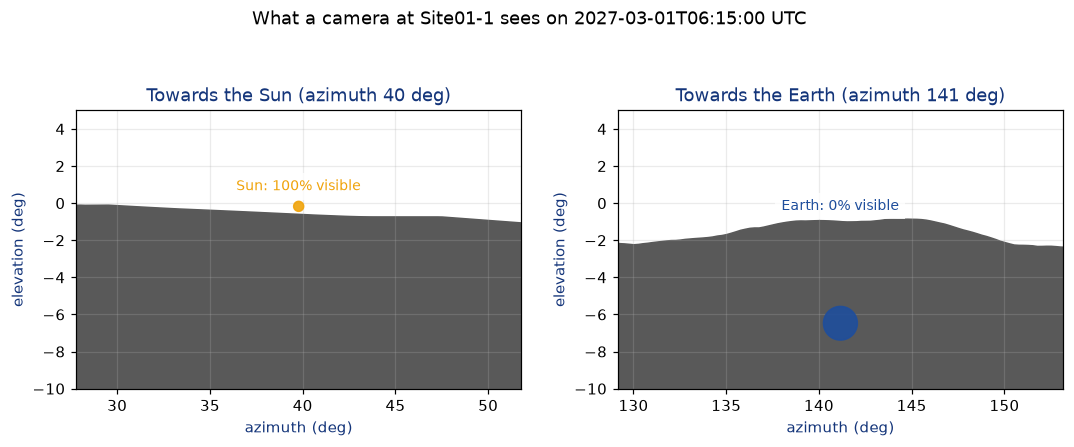

In [23]:
def draw_view(ax, centre, half_width=12):
    lo, hi = centre - half_width, centre + half_width
    a = np.linspace(lo, hi, 1200)
    ax.fill_between(a, -10, horizon_at(a), color="0.35")
    for name, az, el, rad, col, f in (("Sun", sun_az, sun_el, sun_rad, "#f0a30a", sun_f),
                                      ("Earth", earth_az, earth_el, earth_rad, "#1f4e9c", earth_f)):
        # draw the disk at true 1:1 scale: radius is in degrees on both axes
        t = np.linspace(0, 2 * np.pi, 200)
        ax.fill((az + rad * np.cos(t) / np.cos(np.radians(el))), el + rad * np.sin(t), color=col, alpha=0.9, zorder=3)
        ax.annotate(f"{name}: {f*100:.0f}% visible", (az, max(el + rad, float(horizon_at(az))) + 0.6), ha="center", color=col, fontsize=9, zorder=4, bbox=dict(fc="white", ec="none", alpha=0.8))
    ax.set_xlim(lo, hi); ax.set_ylim(-10, 5); ax.set_aspect("equal")
    ax.set_xlabel("azimuth (deg)"); ax.set_ylabel("elevation (deg)")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, centre, name in zip(axes, (sun_az, earth_az), ("Sun", "Earth")):
    draw_view(ax, centre)
    ax.set_title(f"Towards the {name} (azimuth {centre:.0f} deg)")
fig.suptitle(f"What a camera at Site01-1 sees on {UTC} UTC")
fig.tight_layout();

Read the picture: the grey wall is the skyline. The orange disk is the Sun, the blue disk the Earth. Whatever lies above the wall is in view.

At this moment the Sun is **in view**: its whole disk sits above the skyline (by a few tenths of a degree). The Earth, about 6° below flat ground, is **hidden** behind terrain. A solar panel would see light. A camera pointing at Earth would see only rock.

(Each panel is zoomed on one body, with equal scales on both axes, so the disks keep their true shape.)

## Step 5b. Can the Deep Space Network hear us? (DSN in view)

The Moon lander talks to Earth through a big dish on the ground. NASA's **Deep Space Network (DSN)** has three **complexes** spread around the world: Goldstone (California), Madrid (Spain) and Canberra (Australia). Together they can nearly always see the Moon, but not always each one.

DSN in view needs **two** things at the same time:

1. The Earth is above *our* skyline, so our antenna can see it. (The answer from Step 5.)
2. At least one DSN complex sees the Moon more than **10°** above its own horizon. (The 10° keeps the signal away from the thick, noisy air near the ground.)

The first is done. For the second we work on the Earth.

### Step 5b.1. The dishes
Each complex's 70 m dish position is published by NASA's DSN in document *810-005, Module 301* in an Earth-fixed frame (metres).

In [24]:
DSN = {   # NASA/JPL DSN 810-005 Module 301, Earth-fixed Cartesian coordinates, metres
    "Goldstone (DSS-14)": np.array([-2353621.420, -4641341.472,  3677052.318]),
    "Canberra (DSS-43)":  np.array([-4460894.917,  2682361.507, -3674748.152]),
    "Madrid (DSS-63)":    np.array([ 4849092.518,  -360180.348,  4115109.251]),
}
for k, v in DSN.items():
    print(f"{k:20s} distance from Earth's centre {np.linalg.norm(v)/1000:8.2f} km")

Goldstone (DSS-14)   distance from Earth's centre  6371.99 km
Canberra (DSS-43)    distance from Earth's centre  6371.69 km
Madrid (DSS-63)      distance from Earth's centre  6370.05 km


### Step 5b.2. The Moon, as seen from Earth, in Earth's spinning frame
We ask SPICE for the Moon's position from the Earth in the frame `IAU_EARTH`. It is the Earth equivalent of MOON_ME: axes fixed to the spinning Earth, so a dish stands still in it.

In [25]:
moon_from_earth_km, _ = spice.spkpos("MOON", et, "IAU_EARTH", "LT+S", "EARTH")
moon_e = np.array(moon_from_earth_km) * 1000.0
print("Moon from Earth in IAU_EARTH (km):", moon_e / 1000)

Moon from Earth in IAU_EARTH (km): [ 352942.8737   51975.8812 -187104.7156]


### Step 5b.3. "Up" for a dish
The Earth is a little flat (squashed at the poles). The straight-up direction at a dish is the normal to this squashed shape (the **WGS84 ellipsoid**), not the line to the Earth's centre. The difference is up to 0.2°. A short loop finds the geodetic latitude, and with it the up direction.

In [26]:
A_WGS, F_WGS = 6378137.0, 1.0 / 298.257223563

def geodetic_up(xyz):
    x, y, z = xyz
    e2 = F_WGS * (2 - F_WGS)
    p = np.hypot(x, y)
    phi = np.arctan2(z, p * (1 - e2))
    for _ in range(5):
        n = A_WGS / np.sqrt(1 - e2 * np.sin(phi) ** 2)
        h = p / np.cos(phi) - n
        phi = np.arctan2(z, p * (1 - e2 * n / (n + h)))
    lam = np.arctan2(y, x)
    return np.array([np.cos(phi) * np.cos(lam), np.cos(phi) * np.sin(lam), np.sin(phi)]), np.degrees(phi), np.degrees(lam)

MASK_DEG = 10.0
dsn_el = {}
print(f"{'complex':20s} {'geodetic lat':>12s} {'lon':>8s} {'Moon elevation':>15s}  above {MASK_DEG:.0f} deg?")
for name, xyz in DSN.items():
    up_s, la, lo = geodetic_up(xyz)
    v = moon_e - xyz
    el = np.degrees(np.arcsin(v @ up_s / np.linalg.norm(v)))
    dsn_el[name] = el
    print(f"{name:20s} {la:12.3f} {lo:8.3f} {el:14.2f}   {'yes' if el > MASK_DEG else 'no'}")

complex              geodetic lat      lon  Moon elevation  above 10 deg?
Goldstone (DSS-14)         35.426 -116.890         -43.96   no
Canberra (DSS-43)         -35.402  148.981         -17.65   no
Madrid (DSS-63)            40.431   -4.248          20.04   yes


In [27]:
earth_up = earth_f > 0
dsn_up = any(e > MASK_DEG for e in dsn_el.values())
link = earth_up and dsn_up
print(f"Earth above the skyline at the spot : {earth_up}")
print(f"At least one DSN complex sees Moon  : {dsn_up}  ({', '.join(k for k, e in dsn_el.items() if e > MASK_DEG) or 'none'})")
print(f"DSN in view at this moment          : {'YES' if link else 'NO'}")

Earth above the skyline at the spot : False
At least one DSN complex sees Moon  : True  (Madrid (DSS-63))
DSN in view at this moment          : NO


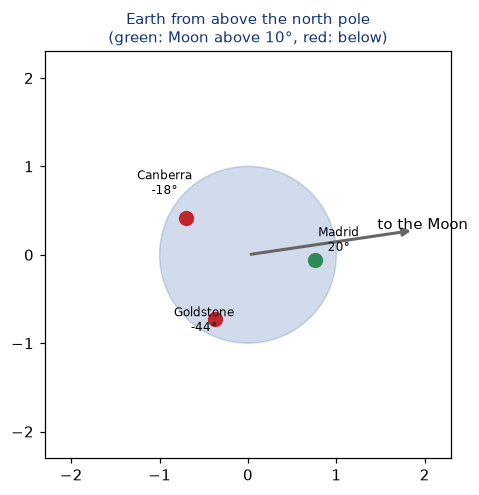

In [28]:
fig, ax = plt.subplots(figsize=(4.8, 4.8))
t = np.linspace(0, 2 * np.pi, 200)
ax.fill(np.cos(t), np.sin(t), color="#1f4e9c", alpha=0.2)
dirn = moon_e[:2] / np.linalg.norm(moon_e[:2])
ax.annotate("", xy=1.9 * dirn, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="0.4", lw=2))
ax.text(*(2.0 * dirn), "to the Moon", ha="center")
for name, xyz in DSN.items():
    p = xyz[:2] / A_WGS
    ok = dsn_el[name] > MASK_DEG
    ax.plot(*p, "o", color="#2e8b57" if ok else "#c0272d", ms=9)
    ax.annotate(f"{name.split()[0]}\n{dsn_el[name]:.0f}°", p * 1.35 + np.array([0, 0.12]), ha="center", fontsize=8)
ax.set_aspect("equal"); ax.set_xlim(-2.3, 2.3); ax.set_ylim(-2.3, 2.3); ax.grid(False)
ax.set_title("Earth from above the north pole\n(green: Moon above 10°, red: below)", fontsize=10);

**What to take from this.** At this moment Madrid sees the Moon 20° up, so the DSN side is fine. But the lander's own skyline hides the Earth, so **no DSN in view**. Both ends must be in view.

**Limits of this model.** It uses SPICE's simple Earth-spin model, which ignores the small wobble called nutation and uses TDB instead of the true Earth clock. A station's rotation can be off by about 0.3°, so an edge of DSN in view can shift by roughly a minute. It does not model weather, antenna schedules or other missions using the dish.

## Check and limits

Does the answer make sense? Three checks.

1. **Light time.** The Earth is about 403 000 km away, and the Sun's light takes about 8 minutes: both match what you know.
2. **The Sun hugs the horizon.** At 89.5°S the Sun can never rise much above the horizon. Its elevation near 0° is the signature of the pole. ✓.
3. **Time scale.** The ET gap was 69.185 s: 69.184 s plus about a millisecond of orbital wobble.

**How this notebook differs from the app**, so you are not surprised:

* The app traces the skyline through a list of maps: a 5 m NASA tile, LOLA 20 m, LOLA 80 m and a global map. The notebook uses just the LOLA 20 m map. Near the spot the app's horizon is finer; the two usually agree within a fraction of a degree.
* The app holds many spots and many times; the notebook has one of each.
* The app's JavaScript does these same steps in the browser. Its tests hold it to this Python reference.

## What's next

**Notebook 2** repeats everything for a whole interval (days or months), and finds the long dark periods, the DSN-in-view windows, and the best landing times. The ideas will be the same. We only add a loop over time.

### Summary

| Step | What we did |
|---|---|
| UTC → ET | `str2et` |
| Frames | MOON_ME (Moon-fixed), IAU_EARTH (Earth-fixed) |
| Local axes | east, north, up |
| Sun, Earth direction | azimuth and elevation |
| Skyline | max angle of the terrain along each azimuth |
| Visible | any part of the disk above the skyline |
| DSN in view | Earth up **and** a complex above 10° (line of sight only) |